In [3]:
import pandas as pd

In [6]:
df = pd.read_csv("client_data.csv")

In [8]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
df = pd.read_csv("client_data.csv")
feature_cols = [
    "acquisition_channel_cost",
    "onboarding_hours",
    "expected_annual_fee",
    "expected_retention_years"
]
target_column = "payback_period_months"
X = df[feature_cols].values
y = df[target_column].values
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
def standardize(X, mean=None, std=None):

    if mean is None:
        mean = X.mean(axis=0)

    if std is None:
        std = X.std(axis=0)
        std[std == 0] = 1.0

    return (X - mean) / std, mean, std
X_train_s, mean, std = standardize(X_train)
X_test_s, _, _ = standardize(
    X_test,
    mean,
    std
)
X_train_b = np.c_[
    np.ones(X_train_s.shape[0]),
    X_train_s
]
X_test_b = np.c_[
    np.ones(X_test_s.shape[0]),
    X_test_s
]
def ridge_normal_equation(X, y, lambda_value):
    n_features = X.shape[1]
    I = np.eye(n_features)
    I[0, 0] = 0
    weights = np.linalg.inv(
        X.T @ X + lambda_value * I
    ) @ X.T @ y
    return weights
linear_weights = ridge_normal_equation(
    X_train_b,
    y_train,
    0
)
linear_predictions = X_test_b @ linear_weights
ridge_weights = ridge_normal_equation(
    X_train_b,
    y_train,
    1
)
ridge_predictions = X_test_b @ ridge_weights


linear_mse = mean_squared_error(
    y_test,
    linear_predictions
)

linear_r2 = r2_score(
    y_test,
    linear_predictions
)
ridge_mse = mean_squared_error(
    y_test,
    ridge_predictions
)
ridge_r2 = r2_score(
    y_test,
    ridge_predictions
)
print("Linear Regression")
print("MSE:", linear_mse)
print("R²:", linear_r2)
print("\nRidge Regression")
print("MSE:", ridge_mse)
print("R²:", ridge_r2)

Linear Regression
MSE: 0.3809666129184301
R²: 0.9830965645406365

Ridge Regression
MSE: 0.38004374403856206
R²: 0.9831375121040694


In [9]:
lambda_values = [0, 0.1, 1, 10]
for lambda_value in lambda_values:
    weights = ridge_normal_equation(
        X_train_b,
        y_train,
        lambda_value
    )
    predictions = X_test_b @ weights
    print("Lambda:", lambda_value)
    print("Weights:", weights)
    print()

Lambda: 0
Weights: [10.073325    4.71866361  1.34937003 -1.33033211 -0.18602606]

Lambda: 0.1
Weights: [10.073325    4.71637505  1.34817559 -1.32684005 -0.18614893]

Lambda: 1
Weights: [10.073325    4.69584576  1.33788611 -1.29596764 -0.18722247]

Lambda: 10
Weights: [10.073325    4.49898636  1.26880264 -1.03180638 -0.19521801]



In [10]:
lambda_values = [0, 0.1, 1, 10]
for lambda_value in lambda_values:
    weights = ridge_normal_equation(
        X_train_b,
        y_train,
        lambda_value
    )
    predictions = X_test_b @ weights
    mse = mean_squared_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)
    print("Lambda:", lambda_value)
    print("MSE:", mse)
    print("R²:", r2)
    print()

Lambda: 0
MSE: 0.3809666129184301
R²: 0.9830965645406365

Lambda: 0.1
MSE: 0.3808667540264915
R²: 0.9831009952657387

Lambda: 1
MSE: 0.38004374403856206
R²: 0.9831375121040694

Lambda: 10
MSE: 0.3780669231841218
R²: 0.9832252233695574



In [44]:
print("Original:")
print(X_train[:3])

print("\nScaled:")
print(X_train_scaled[:3])

Original:
[[5.52350e+03 8.50000e+00 7.57399e+03 3.90000e+00]
 [2.91034e+03 3.90000e+00 5.05772e+03 3.30000e+00]
 [3.49709e+03 4.70000e+00 4.88726e+03 3.10000e+00]]

Scaled:
[[ 1.45524035  1.66775964  1.39851475  0.73937757]
 [-0.32203382 -0.43332609 -0.2193225  -0.15314138]
 [ 0.07702924 -0.06791988 -0.32891985 -0.45064769]]


In [45]:
# Add bias column to original data
X_train_b = np.c_[
    np.ones(X_train.shape[0]),
    X_train
]

# Scale the original features
X_train_scaled = scaler.fit_transform(X_train)

# Add bias column AFTER scaling
X_train_scaled_b = np.c_[
    np.ones(X_train_scaled.shape[0]),
    X_train_scaled
]

# Ridge without scaling
weights_without_scaling = ridge_normal_equation(
    X_train_b,
    y_train,
    10
)

# Ridge with scaling
weights_with_scaling = ridge_normal_equation(
    X_train_scaled_b,
    y_train,
    10
)

print("Without Scaling")
print(weights_without_scaling)

print("\nWith Scaling")
print(weights_with_scaling)

Without Scaling
[ 1.72641253e+00  3.22171943e-03  5.91992102e-01 -8.35569787e-04
 -2.68629222e-01]

With Scaling
[10.073325    4.49898636  1.26880264 -1.03180638 -0.19521801]


In [46]:
print("\nAre the input matrices equal?")
print(np.array_equal(X_train_b, X_train_scaled_b))

print("\nDifference between weights:")
print(weights_without_scaling - weights_with_scaling)


Are the input matrices equal?
False

Difference between weights:
[-8.34691247 -4.49576464 -0.67681053  1.03097081 -0.07341121]


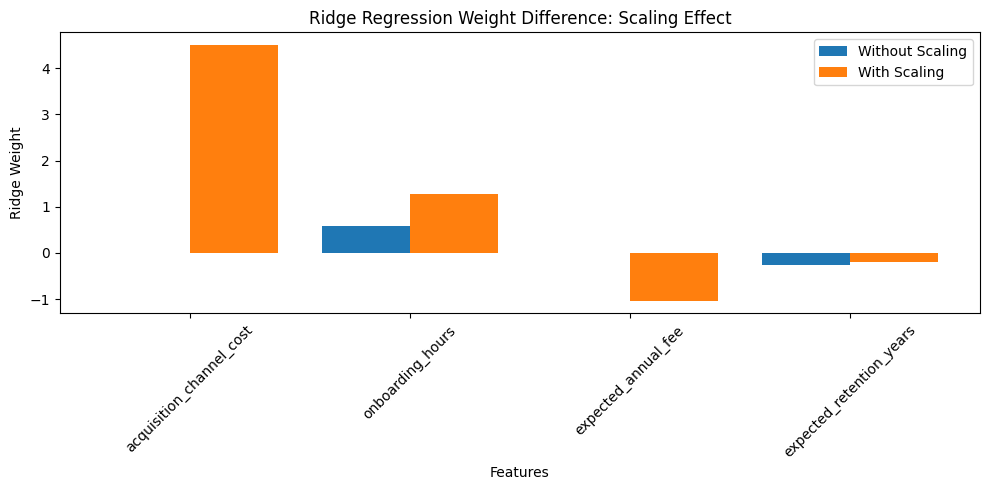

In [47]:
import matplotlib.pyplot as plt
feature_names = feature_cols
weights_without = weights_without_scaling[1:]
weights_with = weights_with_scaling[1:]
x = np.arange(len(feature_names))
plt.figure(figsize=(10, 5))
plt.bar(x - 0.2, weights_without, width=0.4, label="Without Scaling")
plt.bar(x + 0.2, weights_with, width=0.4, label="With Scaling")
plt.xticks(x, feature_names, rotation=45)
plt.xlabel("Features")
plt.ylabel("Ridge Weight")
plt.title("Ridge Regression Weight Difference: Scaling Effect")
plt.legend()
plt.tight_layout()
plt.show()

In [48]:
print("Without Scaling")
print(weights_without_scaling)
print("\nWith Scaling")
print(weights_with_scaling)

Without Scaling
[ 1.72641253e+00  3.22171943e-03  5.91992102e-01 -8.35569787e-04
 -2.68629222e-01]

With Scaling
[10.073325    4.49898636  1.26880264 -1.03180638 -0.19521801]


In [49]:
lambda_values = [0,0.1,1,10]
coefficient_history = []
for lambda_value in lambda_values:
    weights = ridge_normal_equation(
        X_train_scaled_b,
        y_train,
        lambda_value
    )
    coefficient_history.append(weights[1:])

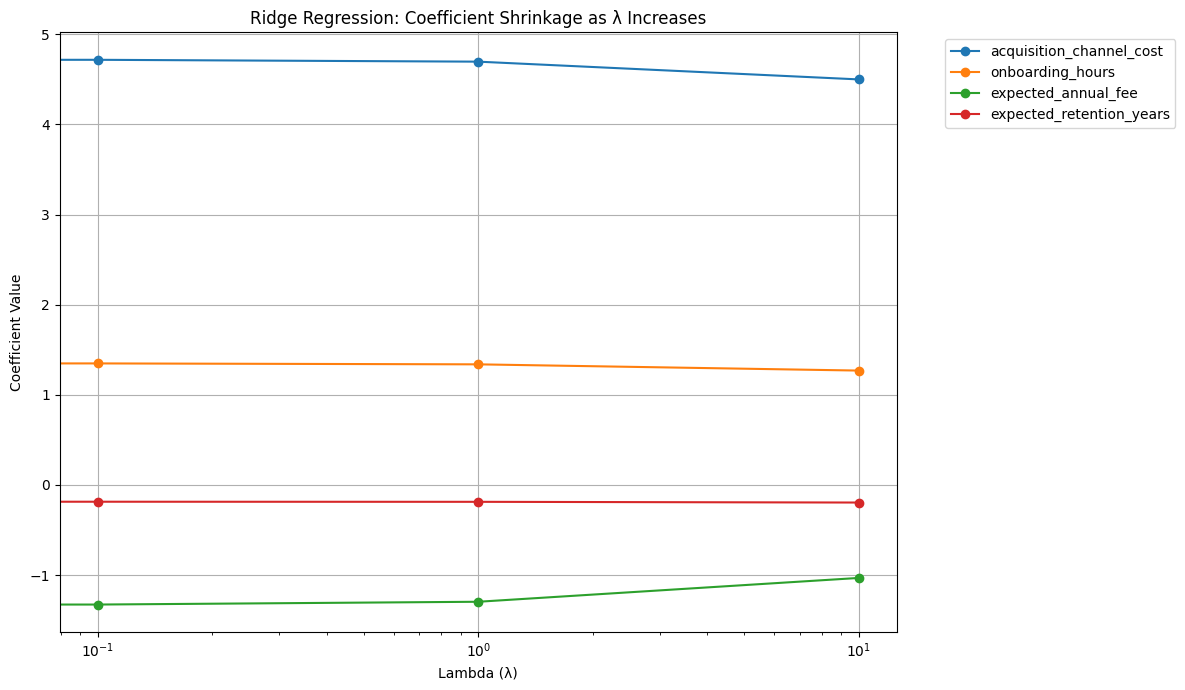

In [50]:
import matplotlib.pyplot as plt
import pandas as pd
coefficient_history = pd.DataFrame(
    coefficient_history,
    columns=feature_cols,
    index=lambda_values
)
plt.figure(figsize=(12, 7))
for feature in feature_cols:
    plt.plot(
        lambda_values,
        coefficient_history[feature],
        marker="o",
        label=feature
    )
plt.xscale("log")
plt.xlabel("Lambda (λ)")
plt.ylabel("Coefficient Value")
plt.title("Ridge Regression: Coefficient Shrinkage as λ Increases")
plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)
plt.grid(True)
plt.tight_layout()
plt.show()

In [51]:
coefficient_history = pd.DataFrame(
    coefficient_history,
    columns=feature_cols,
    index=lambda_values
)

In [19]:
coefficient_history

,acquisition_channel_cost,onboarding_hours,expected_annual_fee,expected_retention_years
0.0,4.718664,1.349370,-1.330332,-0.186026
0.1,4.716375,1.348176,-1.326840,-0.186149
1.0,4.695846,1.337886,-1.295968,-0.187222
10.0,4.498986,1.268803,-1.031806,-0.195218


In [52]:
print(coefficient_history.index)

Index([0.0, 0.1, 1.0, 10.0], dtype='float64')


In [54]:
coefficient_change = (
    coefficient_history.loc[0.0]
    - coefficient_history.loc[10.0]
).abs().sort_values(ascending=False)

print("Features most affected by regularization:")
print(coefficient_change)

Features most affected by regularization:
expected_annual_fee         0.298526
acquisition_channel_cost    0.219677
onboarding_hours            0.080567
expected_retention_years    0.009192
dtype: float64


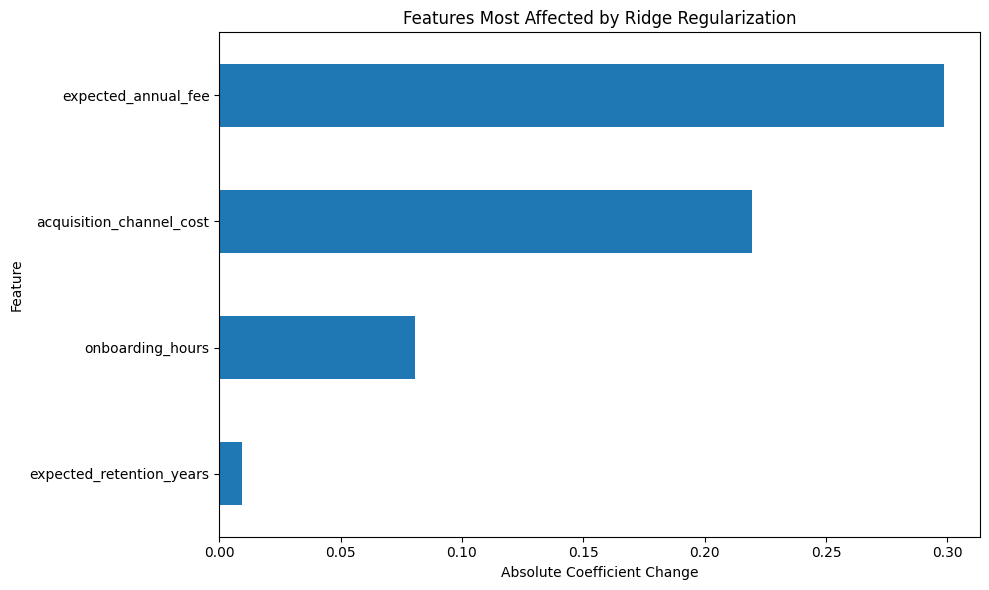

In [55]:
import matplotlib.pyplot as plt
coefficient_change.head(10).sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)
plt.xlabel("Absolute Coefficient Change")
plt.ylabel("Feature")
plt.title("Features Most Affected by Ridge Regularization")
plt.tight_layout()
plt.show()

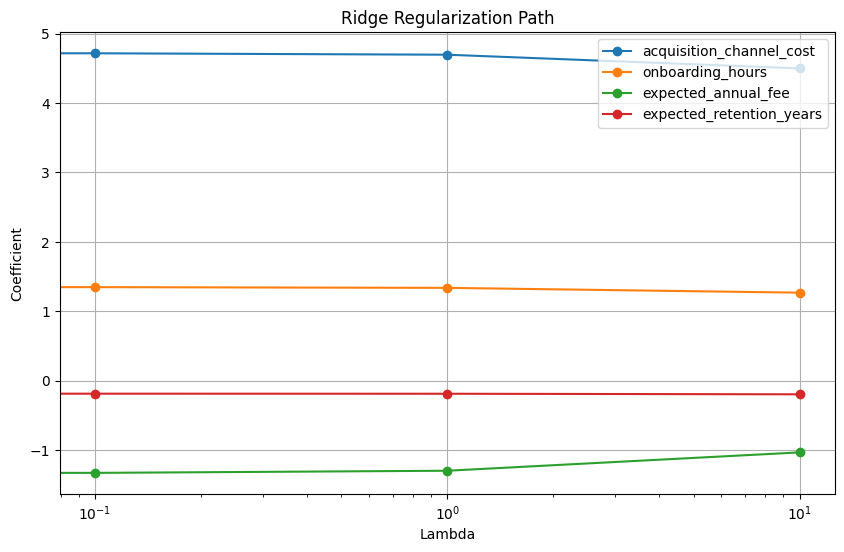

In [22]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
for feature in feature_cols:
    plt.plot(
        lambda_values,
        coefficient_history[feature],
        marker="o",
        label=feature
    )
plt.xscale("log")
plt.xlabel("Lambda")
plt.ylabel("Coefficient")
plt.title("Ridge Regularization Path")
plt.legend()
plt.grid()
plt.show()

In [59]:
lambda_values = [0, 0.001, 0.01, 0.1, 1, 10]
validation_errors = []
training_errors = []

In [60]:
np.random.seed(42)
indices = np.random.permutation(len(X_train_scaled))
folds = np.array_split(indices, 5)

In [61]:
from sklearn.metrics import mean_squared_error
for lambda_value in lambda_values:
    fold_validation_errors = []
    fold_training_errors = []
    for i in range(5):
        validation_indices = folds[i]
        training_indices = np.concatenate(
            [folds[j] for j in range(5) if j != i]
        )
        X_fold_train = X_train_scaled_b[training_indices]
        y_fold_train = y_train[training_indices]
        X_fold_validation = X_train_scaled_b[validation_indices]
        y_fold_validation = y_train[validation_indices]
        weights = ridge_normal_equation(
            X_fold_train,
            y_fold_train,
            lambda_value
        )
        train_predictions = X_fold_train @ weights
        validation_predictions = X_fold_validation @ weights
        train_mse = mean_squared_error(
            y_fold_train,
            train_predictions
        )
        validation_mse = mean_squared_error(
            y_fold_validation,
            validation_predictions
        )
        fold_training_errors.append(train_mse)
        fold_validation_errors.append(validation_mse)
    training_errors.append(
        np.mean(fold_training_errors)
    )
    validation_errors.append(
        np.mean(fold_validation_errors)
    )

In [74]:
cv_results = pd.DataFrame({
    "Lambda": lambda_values,
    "Training_MSE": training_errors,
    "Validation_MSE": validation_errors
})
cv_results



,Lambda,Training_MSE,Validation_MSE
0,0.000,0.390185,0.393957
1,0.001,0.390185,0.393957
2,0.010,0.390185,0.393957
3,0.100,0.390186,0.393957
4,1.000,0.390315,0.394071
5,10.000,0.400628,0.404313


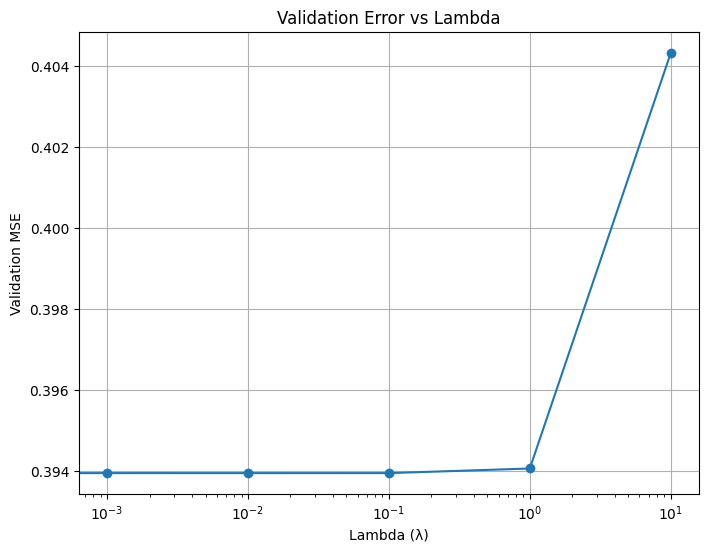

In [62]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))
plt.plot(
    lambda_values,
    validation_errors,
    marker="o"
)
plt.xscale("log")
plt.xlabel("Lambda (λ)")
plt.ylabel("Validation MSE")
plt.title("Validation Error vs Lambda")
plt.grid(True)
plt.show()

In [76]:
for lam in lambda_values:
    print("Regularization strength (λ):", lam)

Regularization strength (λ): 0
Regularization strength (λ): 0.001
Regularization strength (λ): 0.01
Regularization strength (λ): 0.1
Regularization strength (λ): 1
Regularization strength (λ): 10


In [75]:
best_index = np.argmin(validation_errors)
best_lambda = lambda_values[best_index]
print("Best Lambda:", best_lambda)
print("Lowest Validation MSE:", validation_errors[best_index])
print("BEST REGULARIZATION STRENGTH")

Best Lambda: 0.1
Lowest Validation MSE: 0.3939565618070405
BEST REGULARIZATION STRENGTH


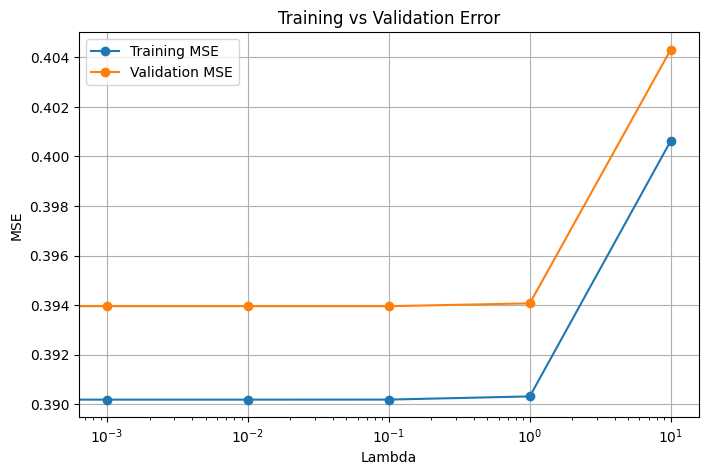

In [67]:
plt.figure(figsize=(8, 5))
plt.plot(
    lambda_values,
    training_errors,
    marker="o",
    label="Training MSE"
)
plt.plot(
    lambda_values,
    validation_errors,
    marker="o",
    label="Validation MSE"
)
plt.xscale("log")
plt.xlabel("Lambda")
plt.ylabel("MSE")
plt.title("Training vs Validation Error")
plt.legend()
plt.grid()
plt.show()

In [68]:
for i in range(len(lambda_values)):
    
    print("Lambda:", lambda_values[i])
    print("Training MSE:", training_errors[i])
    print("Validation MSE:", validation_errors[i])

    gap = validation_errors[i] - training_errors[i]

    print("Training-Validation Gap:", gap)

    print()

Lambda: 0
Training MSE: 0.3901848680151196
Validation MSE: 0.39395692505651647
Training-Validation Gap: 0.0037720570413968812

Lambda: 0.001
Training MSE: 0.39018486814844755
Validation MSE: 0.39395690815087303
Training-Validation Gap: 0.0037720400024254808

Lambda: 0.01
Training MSE: 0.39018488134458307
Validation MSE: 0.3939567680967996
Training-Validation Gap: 0.0037718867522165134

Lambda: 0.1
Training MSE: 0.3901861976374816
Validation MSE: 0.3939565618070405
Training-Validation Gap: 0.003770364169558893

Lambda: 1
Training MSE: 0.39031460130803486
Validation MSE: 0.3940706992417294
Training-Validation Gap: 0.0037560979336945244

Lambda: 10
Training MSE: 0.40062806836123716
Validation MSE: 0.40431275642735737
Training-Validation Gap: 0.003684688066120212



In [69]:
training_errors = []
validation_errors = []

for lambda_value in lambda_values:

    fold_validation_errors = []
    fold_training_errors = []

    for i in range(5):

        validation_indices = folds[i]

        training_indices = np.concatenate(
            [folds[j] for j in range(5) if j != i]
        )

        X_fold_train = X_train_scaled_b[training_indices]
        y_fold_train = y_train[training_indices]

        X_fold_validation = X_train_scaled_b[validation_indices]
        y_fold_validation = y_train[validation_indices]

        weights = ridge_normal_equation(
            X_fold_train,
            y_fold_train,
            lambda_value
        )

        train_predictions = X_fold_train @ weights
        validation_predictions = X_fold_validation @ weights

        train_mse = mean_squared_error(
            y_fold_train,
            train_predictions
        )

        validation_mse = mean_squared_error(
            y_fold_validation,
            validation_predictions
        )

        fold_training_errors.append(train_mse)
        fold_validation_errors.append(validation_mse)

    training_errors.append(
        np.mean(fold_training_errors)
    )

    validation_errors.append(
        np.mean(fold_validation_errors)
    )

In [77]:
for i in range(len(lambda_values)):
    
    print("Lambda:", lambda_values[i])
    print("Training MSE:", training_errors[i])
    print("Validation MSE:", validation_errors[i])

    if validation_errors[i] > training_errors[i]:
        print("Higher variance indicated")
    else:
        print("Training and validation errors are close")

    print()

Lambda: 0
Training MSE: 0.3901848680151196
Validation MSE: 0.39395692505651647
Higher variance indicated

Lambda: 0.001
Training MSE: 0.39018486814844755
Validation MSE: 0.39395690815087303
Higher variance indicated

Lambda: 0.01
Training MSE: 0.39018488134458307
Validation MSE: 0.3939567680967996
Higher variance indicated

Lambda: 0.1
Training MSE: 0.3901861976374816
Validation MSE: 0.3939565618070405
Higher variance indicated

Lambda: 1
Training MSE: 0.39031460130803486
Validation MSE: 0.3940706992417294
Higher variance indicated

Lambda: 10
Training MSE: 0.40062806836123716
Validation MSE: 0.40431275642735737
Higher variance indicated



In [78]:
linear_weights = ridge_normal_equation(
    X_train_scaled_b,
    y_train,
    0
)

In [79]:
optimal_ridge_weights = ridge_normal_equation(
    X_train_scaled_b,
    y_train,
    best_lambda
)

In [80]:
heavy_ridge_weights = ridge_normal_equation(
    X_train_scaled_b,
    y_train,
    100
)

In [81]:
models = {
    "Linear Regression": linear_weights,
    "Ridge Optimal": optimal_ridge_weights,
    "Ridge High Lambda": heavy_ridge_weights
}
for name, weights in models.items():
    predictions = X_test_scaled_b @ weights
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    print("\n", name)
    print("MSE :", mse)
    print("RMSE:", rmse)


 Linear Regression
MSE : 0.3809666129184301
RMSE: 0.6172249289508891

 Ridge Optimal
MSE : 0.3808667540264915
RMSE: 0.617144030212147

 Ridge High Lambda
MSE : 0.5423586433031576
RMSE: 0.7364500277025982


In [82]:
coefficient_comparison = pd.DataFrame({
    "Feature": feature_cols,
    "Linear Regression": linear_weights[1:],
    "Ridge (λ = 0.1)": coefficient_history.loc[0.1].values,
    "Ridge (λ = 10)": coefficient_history.loc[10.0].values
})

coefficient_comparison["Coefficient Change"] = (
    coefficient_comparison["Linear Regression"]
    - coefficient_comparison["Ridge (λ = 10)"]
).abs()

coefficient_comparison = coefficient_comparison.round(4)
coefficient_comparison

,Feature,Linear Regression,Ridge (λ = 0.1),Ridge (λ = 10),Coefficient Change
0,acquisition_channel_cost,4.7187,4.7164,4.4990,0.2197
1,onboarding_hours,1.3494,1.3482,1.2688,0.0806
2,expected_annual_fee,-1.3303,-1.3268,-1.0318,0.2985
3,expected_retention_years,-0.1860,-0.1861,-0.1952,0.0092


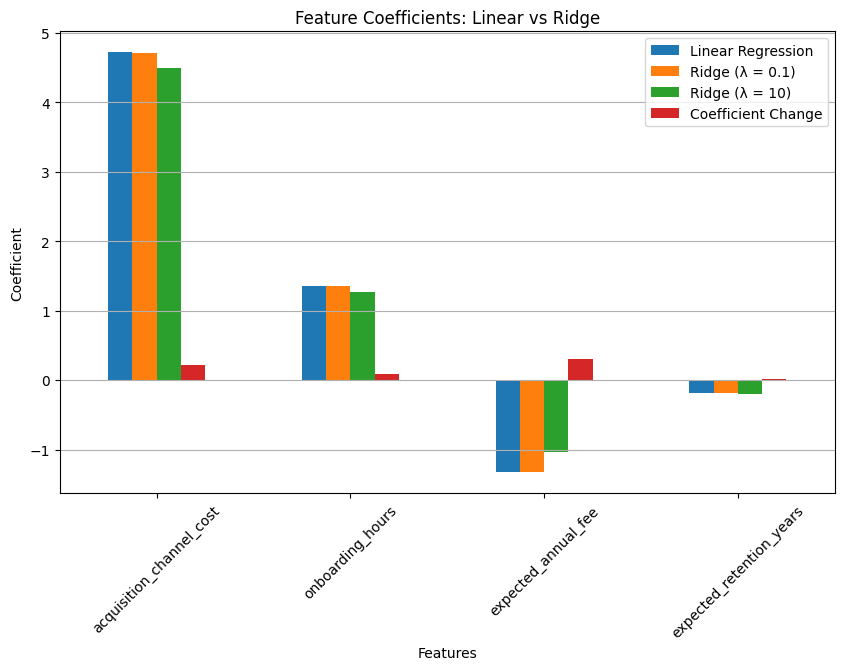

In [83]:
coefficient_comparison.set_index("Feature").plot(
    kind="bar",
    figsize=(10, 6)
)
plt.title("Feature Coefficients: Linear vs Ridge")
plt.xlabel("Features")
plt.ylabel("Coefficient")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.show()

In [88]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
models = {
    "Linear Regression": linear_weights,
    "Ridge Optimal": optimal_ridge_weights,
    "Ridge High Lambda": heavy_ridge_weights
}
for name, weights in models.items():
    predictions = X_test_scaled_b @ weights
    mse=mean_squared_error(y_test, predictions)
    rmse=np.sqrt(mse)
    mae=mean_absolute_error(y_test, predictions)
    r2=r2_score(y_test, predictions)
    print("\n", name)
    print("MSE  :", mse)
    print("RMSE :", rmse)
    print("MAE  :", mae)
    print("R²   :", r2)


 Linear Regression
MSE  : 0.3809666129184301
RMSE : 0.6172249289508891
MAE  : 0.49435329578333387
R²   : 0.9830965645406365

 Ridge Optimal
MSE  : 0.3808667540264915
RMSE : 0.617144030212147
MAE  : 0.4942971030465259
R²   : 0.9831009952657387

 Ridge High Lambda
MSE  : 0.5423586433031576
RMSE : 0.7364500277025982
MAE  : 0.5774072576259796
R²   : 0.975935622671308


In [84]:
best_lambda = lambda_values[np.argmin(validation_errors)]
print("Best Lambda:", best_lambda)

Best Lambda: 0.1


In [100]:
final_weights = ridge_normal_equation(
    X_train_b,
    y_train,
    best_lambda
)

In [101]:
model_data = {
    "weights": final_weights,
    "mean": mean,
    "std": std,
    "features": feature_cols,
    "target": target_column,
    "lambda": best_lambda
}
np.savez("ridge_payback_model.npz", **model_data)
print("Final Ridge model saved successfully.")

Final Ridge model saved successfully.


In [102]:

ridge_model = np.load("ridge_payback_model.npz")
print("Ridge weights:", ridge_model["weights"].shape)
print("Ridge mean:", ridge_model["mean"].shape)
print("Ridge std:", ridge_model["std"].shape)

Ridge weights: (5,)
Ridge mean: (4,)
Ridge std: (4,)
